# 13 — Grids and Euclidean Spaces

Based on §4.2 of Bronstein, Bruna, Cohen, and Veličković, *Geometric Deep Learning: Grids, Groups, Graphs, Geodesics, and Gauges* (proto-book, pp. 35–39). This notebook develops the link between grids, translations, circulant matrices, convolution, and Fourier analysis. The final appendix explains the Fast Fourier Transform (FFT), mentioned in the second-to-last paragraph on p. 38.

We revisit important ideas from earlier notebooks where needed:
- `02_groups.ipynb`: group actions and equivariance;
- `03_linear_spaces.ipynb`: linear maps and bases;
- `06_functional_analysis.ipynb`: operators and eigenvectors;
- `07_fourier_analysis.ipynb`: Fourier bases and spectral diagonalization;
- `08_wavelets_and_multiscale_signal_processing.ipynb`: signal processing and multiscale representations;
- `09_geometric_priors-ii.ipynb`: locality and coarsening;
- `11_graph_theory_fundamentals.ipynb` and `12_gnn_1.ipynb`: graph neighbourhoods and message passing.

Our goal is to derive why convolution is the natural linear operation when translation is the relevant symmetry—not merely to state that CNNs use convolution.

## 1. What makes a grid special?

A grid is a graph with highly regular adjacency. On a general graph, a node has neighbours but they usually have no canonical order. On a grid, coordinates supply a fixed order: in one dimension, a point has a left and a right neighbour.

This changes the form of a local operation:
- **General graph:** aggregate neighbour information without depending on an arbitrary neighbour ordering.
- **Grid:** use relative position, so left, centre, and right can have different weights.

A grid is therefore a stronger prior than a bare set: it tells us which samples are adjacent and what their relative positions mean.

**Example:** an image filter can give different weights to pixels left and right of the current pixel.

**Non-example:** in an unordered set of measurements, “left neighbour” has no intrinsic meaning unless additional structure is supplied.

## 2. A one-dimensional periodic grid

For clean algebra, assume periodic boundary conditions and identify the grid with

$$
\Omega=\mathbb Z_n=\{0,1,\ldots,n-1\},
$$

with indices interpreted modulo \(n\). Thus, position \(0\)'s left neighbour is \(n-1\). This is a mathematical convenience, not a universal property of images; practical layers may instead use zero padding, reflection padding, or valid convolutions.

Periodic boundary condition allows to define a transformation
$$
\begin{matrix}
& g: \Omega \to \Omega \\
 & u \mapsto (u + 1)\text{ mod }n
\end{matrix}
$$

**Exercise:** What is $g^{-1}$? What is $g^k$? Conclude that the associated translation group is $Z_n$ itself.

Recall, $g$ also acts on signals $g: \chi \to \chi$ by $x \mapsto gx: \Omega \to \mathbb{R}$, which is given by $gx: u \to x(g^{-1}u)$.

**Exercise:** Check that $g: \chi \to \chi$ is a linear transformation. 

**Exercise:** For, the grid of size $n, \chi = \{x: \Omega \to \mathbb{R}\} \cong \mathbb{R}^n$.Calculate it's matrix. This matrix is called the *shift operator*. Compare this with the adjacency matrix of the grid, thinking it as a graph.

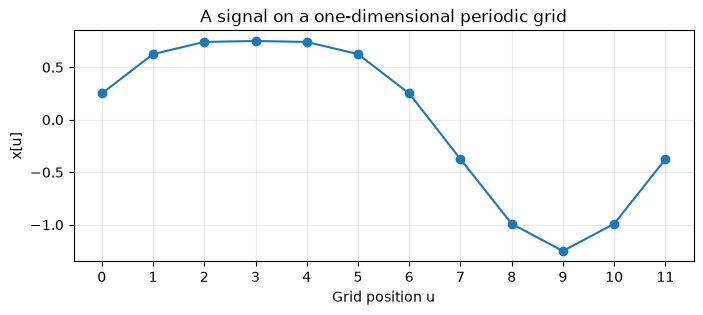

In [1]:
import numpy as np
import matplotlib.pyplot as plt

n = 12
u = np.arange(n)
signal = np.sin(2 * np.pi * u / n) + 0.25 * np.cos(4 * np.pi * u / n)

plt.figure(figsize=(8, 3))
plt.plot(u, signal, marker="o")
plt.xticks(u)
plt.xlabel("Grid position u")
plt.ylabel("x[u]")
plt.title("A signal on a one-dimensional periodic grid")
plt.grid(alpha=0.25)
plt.show()

## 3. A shared local rule and its matrix

At every grid point \(u\), apply the same local linear rule

$$
(Fx)_u=\theta_{-1}x_{u-1}+\theta_0x_u+\theta_1x_{u+1}.
$$

The coefficients are shared across positions. This is **weight sharing**: the same local pattern detector is used wherever the pattern occurs. Under periodic boundaries, the resulting matrix has repeated diagonals and wrap-around entries.

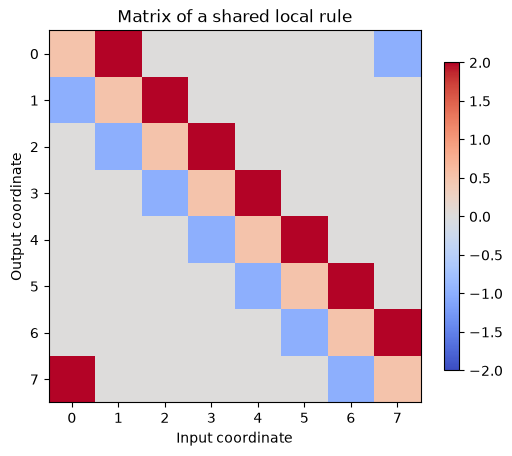

[[ 0.5  2.   0.   0.   0.   0.   0.  -1. ]
 [-1.   0.5  2.   0.   0.   0.   0.   0. ]
 [ 0.  -1.   0.5  2.   0.   0.   0.   0. ]
 [ 0.   0.  -1.   0.5  2.   0.   0.   0. ]
 [ 0.   0.   0.  -1.   0.5  2.   0.   0. ]
 [ 0.   0.   0.   0.  -1.   0.5  2.   0. ]
 [ 0.   0.   0.   0.   0.  -1.   0.5  2. ]
 [ 2.   0.   0.   0.   0.   0.  -1.   0.5]]


In [2]:
n = 8
theta_left, theta_center, theta_right = -1.0, 0.5, 2.0
F = np.zeros((n, n))

# Build F so (F x)[u] uses x[u-1], x[u], x[u+1], modulo n.
for u in range(n):
    F[u, (u - 1) % n] += theta_left
    F[u, u] += theta_center
    F[u, (u + 1) % n] += theta_right

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(F, cmap="coolwarm", vmin=-2, vmax=2)
ax.set_title("Matrix of a shared local rule")
ax.set_xlabel("Input coordinate")
ax.set_ylabel("Output coordinate")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.show()
print(F)

This repeating multi-diagonal structure is the matrix form of a shared local rule. In a CNN, a small kernel is shared across spatial positions. Multiple input/output channels replace scalar coefficients by matrices between channel spaces.

## 4. Shift operators and translation equivariance

Let \(S\) be the right-shift operator,

$$
(Sx)_u=x_{u-1\pmod n}.
$$

An operator \(F\) is translation-equivariant if

$$
FS=SF.
$$

This means shifting the input and then applying \(F\) equals applying \(F\) and then shifting the output. It is **equivariance**, not invariance: the output moves with the input. This means that to understand equivariance, we need to understand the spectral properties of $S$. Since, $S^{\ast}S = SS^{\ast} = I$, (or $S$ is normal) by the Spectral Theorem, $S$ can be diagonalized in a complex basis.

The proto-book's key algebraic observation is that a matrix is circulant precisely when it commutes with the cyclic shift (under a compatible convention). Convolution is therefore the natural linear translation-equivariant operation on a periodic grid. See `02_groups.ipynb` for the general symmetry language and `07_fourier_analysis.ipynb` for spectral operators.

In [3]:
# Construct the right shift S: (S x)[u] = x[u-1 mod n].
S = np.zeros((n, n))
for u in range(n):
    S[u, (u - 1) % n] = 1.0

print("||F S - S F||_F =", np.linalg.norm(F @ S - S @ F))
assert np.allclose(F @ S, S @ F)

||F S - S F||_F = 0.0


## 5. Circulant matrices and circular convolution

A circulant matrix is built by cyclically shifting the same coefficient vector across rows. It implements **circular convolution**. With the convention used here,

$$
(x *_c \theta)_u=\sum_{v=0}^{n-1}x_v\theta_{u-v\pmod n}.
$$

Indices wrap around at the boundaries, unlike ordinary linear convolution.

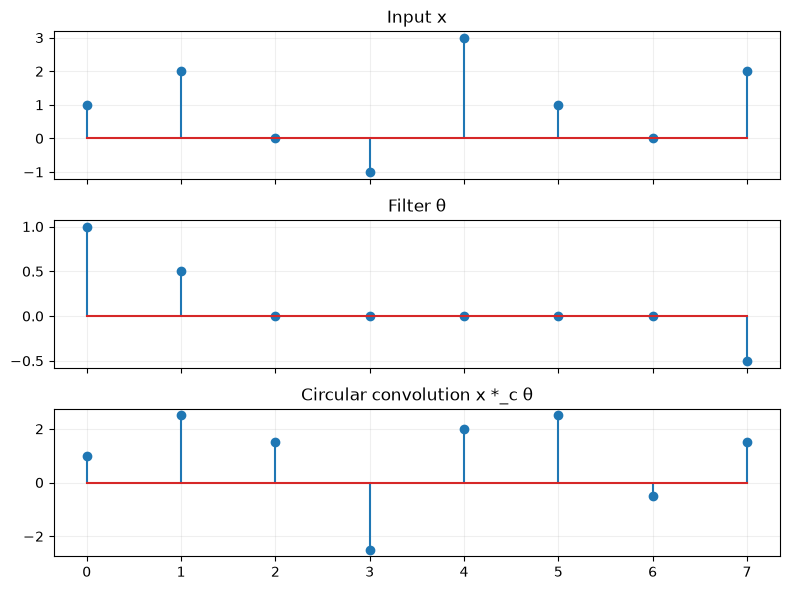

In [4]:
def circular_convolution(x, kernel):
    # Direct O(n^2) implementation of circular convolution.
    x, kernel = np.asarray(x), np.asarray(kernel)
    if x.shape != kernel.shape:
        raise ValueError("x and kernel must have equal length here.")
    n = len(x)
    return np.array([
        sum(x[v] * kernel[(u - v) % n] for v in range(n))
        for u in range(n)
    ])

x_demo = np.array([1., 2., 0., -1., 3., 1., 0., 2.])
theta_demo = np.array([1., 0.5, 0., 0., 0., 0., 0., -0.5])
y_demo = circular_convolution(x_demo, theta_demo)

fig, axes = plt.subplots(3, 1, figsize=(8, 6), sharex=True)
for ax, values, title in zip(
    axes, [x_demo, theta_demo, y_demo],
    ["Input x", "Filter θ", "Circular convolution x *_c θ"]
):
    ax.stem(np.arange(len(values)), values)
    ax.set_title(title)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 6. Why convolution is translation-equivariant

Circular convolution satisfies

$$
S(x *_c\theta)=(Sx)*_c\theta.
$$

The same filter can be applied before or after a shift. Conversely, every linear operator on a periodic one-dimensional grid that commutes with the cyclic shift is circulant, hence a circular convolution operator. Convolution is thus characterized by the symmetry, not merely chosen as a convenient operation.

In [5]:
def right_shift(x):
    return np.roll(x, 1)

lhs = right_shift(circular_convolution(x_demo, theta_demo))
rhs = circular_convolution(right_shift(x_demo), theta_demo)
print("Maximum discrepancy:", np.max(np.abs(lhs - rhs)))
assert np.allclose(lhs, rhs)

Maximum discrepancy: 0.0


## 7. Fourier modes diagonalize the shift

The Fourier modes are

$$
\phi_k[u]= \frac{1}{\sqrt n}e^{2\pi i ku/n},\qquad k=0,\ldots,n-1.
$$

A shift multiplies each mode by a phase:

$$
(S\phi_k)[u]=\phi_k[u-1]=e^{-2\pi i k/n}\phi_k[u].
$$

Thus the Fourier modes are eigenvectors of the shift. Since circulant matrices commute with the shift, they share its Fourier eigenbasis. In that basis, convolution becomes frequency-wise multiplication. This repeats the spectral result from `07_fourier_analysis.ipynb`, now derived from translation symmetry.

Eigenvector residual: 3.5327080320384943e-16


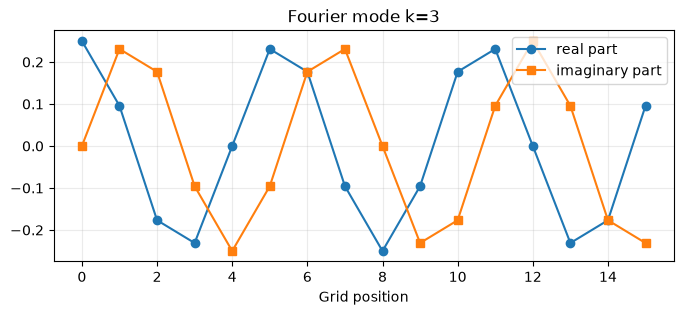

In [6]:
n_fourier = 16
u = np.arange(n_fourier)
k = 3
phi = np.exp(2j * np.pi * k * u / n_fourier) / np.sqrt(n_fourier)
Sphi = np.roll(phi, 1)
eigenvalue = np.exp(-2j * np.pi * k / n_fourier)

print("Eigenvector residual:", np.max(np.abs(Sphi - eigenvalue * phi)))
assert np.allclose(Sphi, eigenvalue * phi)

plt.figure(figsize=(8, 3))
plt.plot(u, phi.real, marker="o", label="real part")
plt.plot(u, phi.imag, marker="s", label="imaginary part")
plt.title(f"Fourier mode k={k}")
plt.xlabel("Grid position")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 8. DFT and the convolution theorem

Let $\Phi$ be the unitary Fourier matrix. The discrete Fourier transform changes coordinates:

$$
\widehat{x}=\Phi^*x,\qquad x=\Phi\widehat{x}.
$$

For a circulant operator,

$$
C(\theta)=\Phi\,\operatorname{diag}(\widehat{\theta})\,\Phi^*.
$$

Therefore convolution becomes elementwise multiplication in the frequency domain. Normalization conventions matter: with a unitary DFT, the circular-convolution theorem carries a factor of \(\sqrt n\); with the usual unnormalized forward DFT and inverse divided by \(n\), it takes the familiar no-extra-factor form.

In [7]:
def circular_convolution(x, kernel):
    x, kernel = np.asarray(x), np.asarray(kernel)
    n = len(x)
    return np.array([sum(x[v] * kernel[(u-v) % n] for v in range(n))
                     for u in range(n)])

rng = np.random.default_rng(0)
n = 8
x = rng.normal(size=n)
theta = np.random.default_rng(1).normal(size=n)
y = circular_convolution(x, theta)

# NumPy uses an unnormalized forward FFT.
X_hat = np.fft.fft(x)
T_hat = np.fft.fft(theta)
Y_hat = np.fft.fft(y)
print("Convolution theorem residual:",
      np.max(np.abs(Y_hat - X_hat * T_hat)))
assert np.allclose(Y_hat, X_hat * T_hat)

Convolution theorem residual: 9.930136612989092e-16


## 9. From 1D grids to images

A two-dimensional grid is a tensor product of one-dimensional grids. Its Fourier basis has two frequency coordinates, often interpreted as horizontal and vertical frequency. A 2D kernel can therefore respond differently to horizontal, vertical, and diagonal patterns.

For a generic graph, by contrast, a spectral basis depends on the graph itself; there may be no universal horizontal/vertical frequency interpretation. The proto-book returns to this limitation in its later discussion of graphs and manifolds.

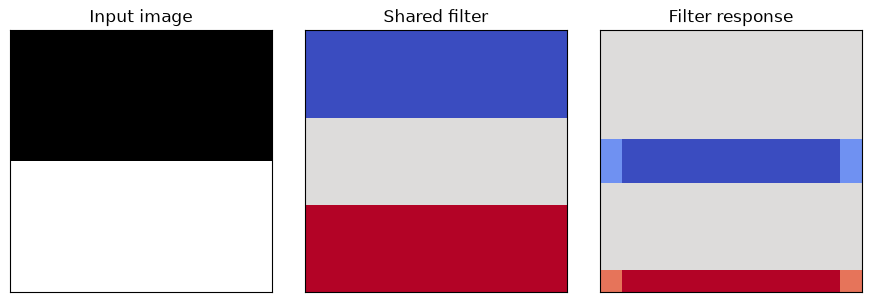

In [8]:
from scipy.signal import convolve2d

image = np.zeros((12, 12))
image[6:, :] = 1.0
kernel_2d = np.array([[-1., -1., -1.],
                      [ 0.,  0.,  0.],
                      [ 1.,  1.,  1.]])
response = convolve2d(image, kernel_2d, mode="same", boundary="fill", fillvalue=0)

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, arr, title in zip(axes, [image, kernel_2d, response],
                          ["Input image", "Shared filter", "Filter response"]):
    ax.imshow(arr, cmap="gray" if title == "Input image" else "coolwarm")
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

## 10. Examples and non-examples

**Examples**
- A shared finite kernel applied at every image location.
- A circulant matrix acting on a periodic 1D signal.
- A linear translation-equivariant layer on a fixed grid.
- Fourier-domain filtering by multiplying each frequency coefficient by a transfer function.

**Non-examples / caveats**
- A generic dense matrix is not usually translation-equivariant.
- A fully connected layer with independent weights at each position does not automatically respect translations.
- A convolutional layer is generally equivariant, not invariant; global pooling may produce invariance.
- Circular convolution and zero-padded convolution use different boundary conventions.
- FFT is an algorithm for evaluating the DFT efficiently, not a new transform or symmetry.

## 11. Exercises

1. For \(n=6\), write the cyclic shift matrix \(S\) and verify \(S^n=I\).
2. Construct a circulant matrix and verify that it commutes with \(S\).
3. Explain why shared coefficients encode a translation prior.
4. Demonstrate that a generic random matrix does not commute with \(S\).
5. Compare circular convolution with linear convolution and explain the boundary difference.
6. Verify the convolution theorem numerically under one consistent DFT convention.
7. Extend the local rule to 2D and identify horizontal, vertical, and diagonal offsets.
8. Explain the difference between equivariance in a convolutional layer and invariance in a classifier.

# Appendix A — The Fast Fourier Transform (FFT)

The **discrete Fourier transform (DFT)** is a mathematical transform. The **fast Fourier transform (FFT)** is a family of algorithms that computes the same DFT more efficiently.

The direct DFT computes each of \(n\) frequency coefficients by summing over \(n\) samples, requiring \(O(n^2)\) arithmetic operations. FFT algorithms exploit the algebraic structure of the Fourier matrix to reduce this to \(O(n\\log n)\) for standard sizes.

## A.1 The DFT formula

$$
X_k=\sum_{j=0}^{n-1}x_j e^{-2\pi i jk/n},\qquad k=0,\ldots,n-1,
$$

with inverse

$$
x_j=\frac1n\sum_{k=0}^{n-1}X_k e^{2\pi i jk/n}.
$$

The DFT expresses a finite signal in discrete complex-exponential modes.

In [9]:
def dft_direct(x):
    # Direct matrix-based DFT: O(n^2).
    x = np.asarray(x, dtype=complex)
    n = len(x)
    k = np.arange(n)[:, None]
    j = np.arange(n)[None, :]
    W = np.exp(-2j * np.pi * k * j / n)
    return W @ x

x = np.random.default_rng(12).normal(size=8)
X_direct = dft_direct(x)
X_fft = np.fft.fft(x)
print("Maximum discrepancy:", np.max(np.abs(X_direct - X_fft)))
assert np.allclose(X_direct, X_fft)

Maximum discrepancy: 6.404745667978754e-15


## A.2 The divide-and-conquer idea

For even \(n\), split the input into even-indexed and odd-indexed samples. Let $E_k$ and $O_k$ be their length-$n/2$ DFTs. With $\omega_n^k=e^{-2\\pi i k/n}$,

$$
X_k=E_k+\omega_n^kO_k,
$$

$$
X_{k+n/2}=E_k-\omega_n^kO_k,\qquad 0\le k<n/2.
$$

Two smaller transforms are reused to form the larger transform. Recursively splitting the problem yields the radix-2 Cooley–Tukey FFT. Its recurrence is

$$
T(n)=2T(n/2)+O(n),
$$

so \(T(n)=O(n\\log n)\), rather than \(O(n^2)\).

In [10]:
def fft_radix2(x):
    # Pedagogical recursive radix-2 FFT; n must be a power of two.
    x = np.asarray(x, dtype=complex)
    n = len(x)
    if n == 0 or (n & (n - 1)) != 0:
        raise ValueError("Input length must be a positive power of two.")
    if n == 1:
        return x.copy()

    even = fft_radix2(x[::2])
    odd = fft_radix2(x[1::2])
    twiddle = np.exp(-2j * np.pi * np.arange(n // 2) / n) * odd
    return np.concatenate([even + twiddle, even - twiddle])

x = np.random.default_rng(7).normal(size=16)
print("Radix-2 FFT residual:",
      np.max(np.abs(fft_radix2(x) - np.fft.fft(x))))
assert np.allclose(fft_radix2(x), np.fft.fft(x))

Radix-2 FFT residual: 6.661338147750939e-16


## A.3 A small timing experiment

This is illustrative rather than a rigorous benchmark: timing depends on hardware, library implementation, and overhead. It compares a direct DFT with NumPy's optimized FFT.

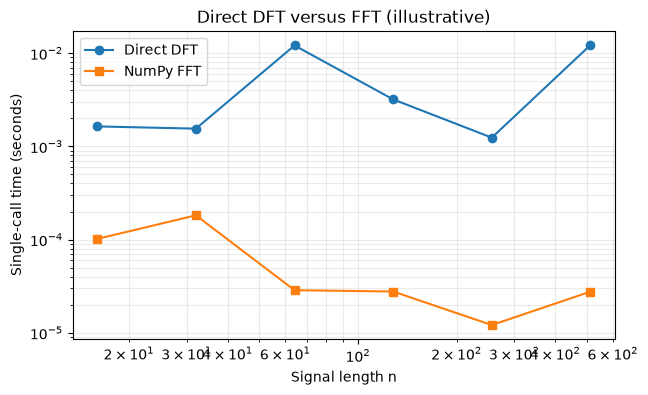

In [11]:
import time

sizes = [16, 32, 64, 128, 256, 512]
direct_times, fft_times = [], []
for n in sizes:
    x = np.random.default_rng(n).normal(size=n)
    start = time.perf_counter()
    dft_direct(x)
    direct_times.append(time.perf_counter() - start)
    start = time.perf_counter()
    np.fft.fft(x)
    fft_times.append(time.perf_counter() - start)

plt.figure(figsize=(7, 4))
plt.loglog(sizes, direct_times, marker="o", label="Direct DFT")
plt.loglog(sizes, fft_times, marker="s", label="NumPy FFT")
plt.xlabel("Signal length n")
plt.ylabel("Single-call time (seconds)")
plt.title("Direct DFT versus FFT (illustrative)")
plt.legend()
plt.grid(True, which="both", alpha=0.25)
plt.show()

## A.4 FFT-based convolution

For compatible conventions,

$$
x *_c \theta=\mathcal F^{-1}\big(\mathcal F(x)\odot\mathcal F(\theta)\big),
$$

with normalization factors depending on the DFT convention. The workflow is: transform the signal, transform the filter, multiply frequency coefficients, then invert. For long signals this can be cheaper than direct \(O(n^2)\) convolution. For short learned kernels, spatial convolution may be faster and keeps locality explicit; libraries select implementations according to sizes and hardware.

The proto-book's point on p. 38 is that the Fourier matrix has enough algebraic structure for transforms to be computed in \(O(n\\log n)\). FFT efficiency helps explain the popularity of frequency-domain filtering; the geometric argument that convolution is linear translation-equivariance is a separate point.

## References

1. M. M. Bronstein, J. Bruna, T. Cohen, and P. Veličković, “Geometric Deep Learning: Grids, Groups, Graphs, Geodesics, and Gauges,” §4.2, pp. 35–39. https://arxiv.org/abs/2104.13478
2. J. W. Cooley and J. W. Tukey, “An Algorithm for the Machine Calculation of Complex Fourier Series,” *Mathematics of Computation* 19(90), 1965, pp. 297–301.
3. R. N. Bracewell, *The Fourier Transform and Its Applications*.
4. `07_fourier_analysis.ipynb` and `08_wavelets_and_multiscale_signal_processing.ipynb` in this repository.